# Dataset screening

Every structure (default config, no balancing) on every dataset. A useful dataset spreads the
structures apart by more than seed noise and is neither solved by all nor by none.
Training is resumable: the cell only runs what is missing (each run ~10-20 min on one CPU core).

In [1]:
import sys, os, json
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "backbone").exists():        # works from notebooks/ or models/<s>/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
from backbone.paths import DATA_ROOT, RUNS_ROOT, FIG_ROOT
import pandas as pd
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
print("project:", ROOT); print("data:", DATA_ROOT); print("runs:", RUNS_ROOT)

project: /home/claude/work/MoE_Structures_v2
data: /home/claude/work/MoE_Structures_v2/_data
runs: /home/claude/work/MoE_Structures_v2/runs


In [2]:
RUN = False   # set True to (re)run missing trials here; the sweep can also be run from a terminal
if RUN:
    import subprocess
    subprocess.run([sys.executable, "-m", "experiments.sweep", "--phase", "screen", "--seeds", "0", "--workers", "2"])

In [3]:
from analysis.collect import load_results, separation
from analysis import figures as F
df = load_results(RUNS_ROOT)
scr = df[(df.variant == "default") & (df.balance == "none")]
display(scr.pivot_table(index="structure", columns="dataset", values="test_acc").round(3))
sep = separation(df); display(sep.round(3))

dataset,copy,fact,logic,mix,mod,mqar,rev
structure,,,,,,,
dense,1.000,0.542,0.562,0.636,0.298,0.124,1.000
dense_wide,1.000,0.985,0.550,0.186,0.321,0.124,1.000
mita,0.936,0.222,0.572,0.578,0.248,0.124,0.958
moa,1.000,0.352,0.552,0.638,0.215,0.123,1.000
moe,1.000,0.441,0.577,0.631,0.269,0.124,1.000
moh,1.000,0.520,0.579,0.639,0.281,0.122,1.000
mom,1.000,0.009,0.556,0.024,0.014,0.016,0.508
momha,1.000,0.453,0.571,0.638,0.241,0.123,1.000


,dataset,n_struct,mean,spread,range,seed_sd,score,ceiling,floor,best,worst
1,fact,8,0.440,0.282,0.976,0.059,4.763,0.125,0.125,dense_wide,mom
3,mix,8,0.496,0.246,0.615,0.035,6.937,0.000,0.125,moh,mom
6,rev,8,0.933,0.172,0.492,0.246,0.701,0.750,0.000,dense,mom
4,mod,8,0.236,0.096,0.306,0.026,3.674,0.000,0.125,dense_wide,mom
5,mqar,8,0.110,0.038,0.109,0.001,30.769,0.000,0.125,mita,mom
0,copy,8,0.992,0.022,0.064,0.014,1.576,0.875,0.000,dense,mita
2,logic,8,0.565,0.011,0.030,0.011,1.059,0.000,0.000,moh,dense_wide


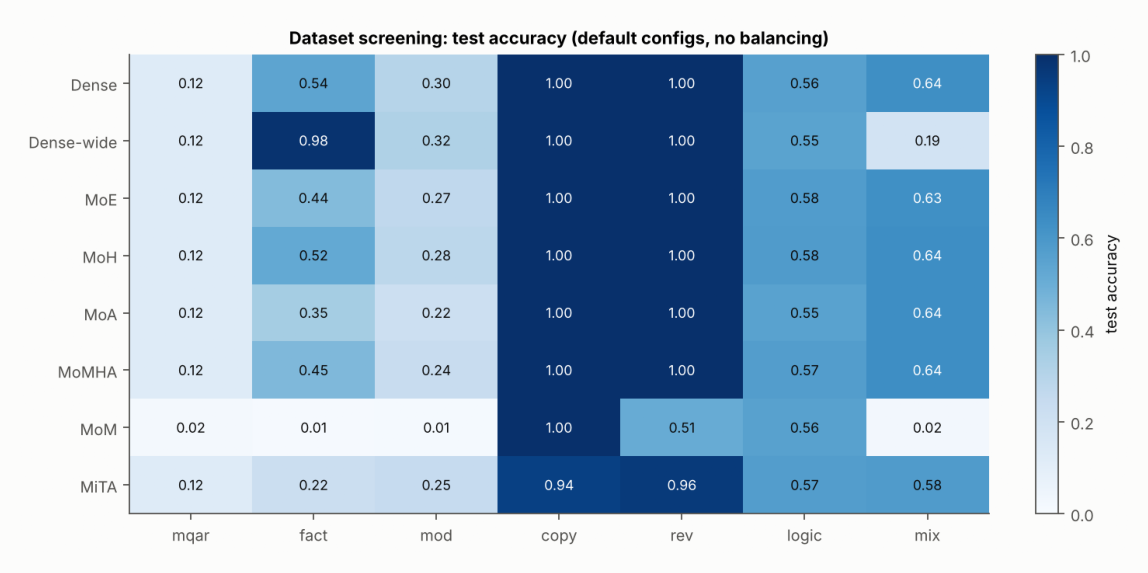

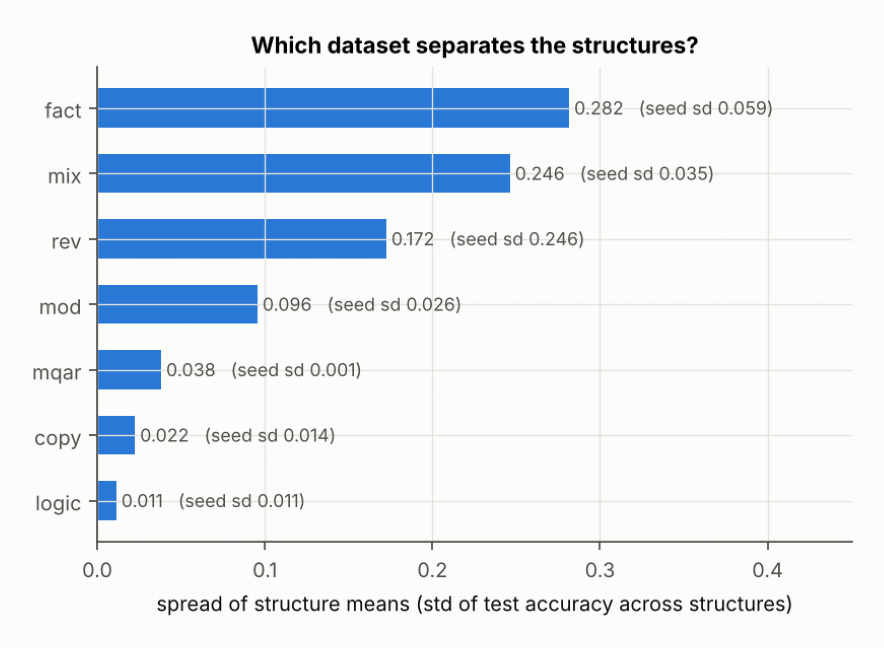

In [4]:
import matplotlib.pyplot as plt, matplotlib.image as mpimg
for p in [F.screen_heatmap(df), F.screen_separation(sep)]:
    plt.figure(figsize=(9, 5)); plt.imshow(mpimg.imread(p)); plt.axis("off"); plt.show()